In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


### Целевая функция:

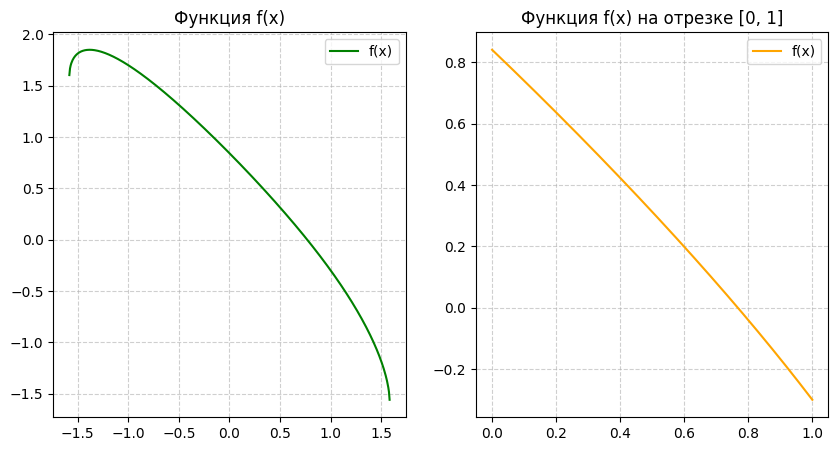

In [2]:
func = lambda x: np.sin(np.sqrt(1 - 0.4*x**2)) - x
a = 0
b = 1

x_full_func = np.linspace(-1.6, 1.6, 500)
valid_mask = ((1 - 0.4*x_full_func**2) >= 0)
x_valid = x_full_func[valid_mask]
x = np.linspace(a, b, 1000)
    
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].plot(x_valid, func(x_valid), c='green', label='f(x)')
axes[0].set_title("Функция f(x)")
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

axes[1].plot(x, func(x), c='orange', label='f(x)')
axes[1].set_title("Функция f(x) на отрезке [0, 1]")
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()
plt.savefig('func.png', dpi=300)
plt.show()

### Реализация моделей:

In [3]:
# Shallow MLP (Малая полносвязная сеть)
def shallowMLP():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model


# Deep MLP (Глубокий персептрон)
def deepMLP():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model

# 1D CNN (Сверточная сеть)
def conv1Dnet():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(32, activation='relu'),
        layers.Reshape((32, 1)),
        layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
        layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
        layers.Flatten(),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model

# ResNet-MLP (Сеть с остаточными связями)
def resnetMLP():
    inputs = layers.Input(shape=(1,))
    x = layers.Dense(64, activation='relu')(inputs)
    for _ in range(2):
        residual = x
        x = layers.Dense(64, activation='relu')(x)
        x = layers.Dense(64)(x)
        x = layers.Add()([x, residual])
        x = layers.Activation('relu')(x)
    outputs = layers.Dense(1)(x)
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='mse')
    return model

    


### Обучающая и тестовая выборки:

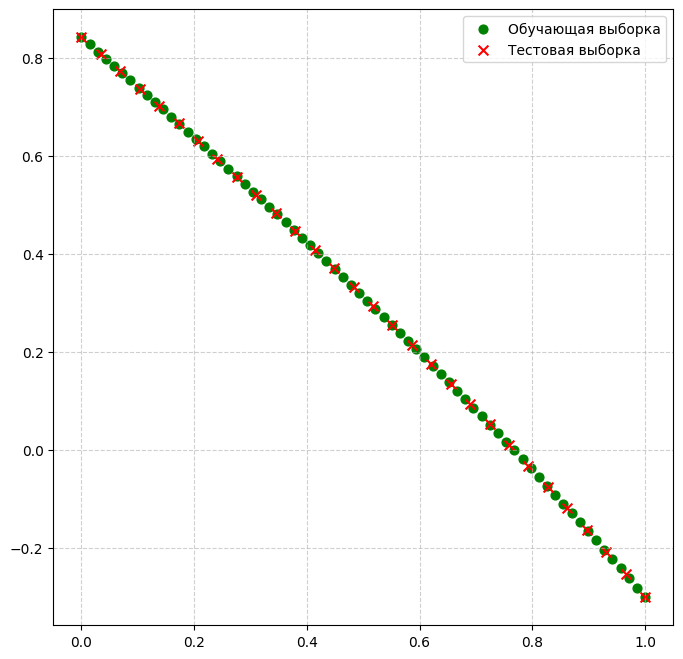

In [68]:
N_TRAIN = 70
N_TEST = 30

x_train = np.linspace(a, b, N_TRAIN).reshape(-1, 1)
y_train = func(x_train).reshape(-1, 1)
x_test = np.linspace(a, b, N_TEST).reshape(-1, 1)
y_test = func(x_test).reshape(-1, 1)

plt.figure(figsize=(8, 8))
plt.scatter(x_train, y_train, s=40, marker='o', c='green', label='Обучающая выборка')
plt.scatter(x_test, y_test, s=50, marker='x', c='red', label='Тестовая выборка')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('samples.png', dpi = 300)
plt.show()


### Обучение и настройка моделей:

In [48]:
epochs = 30
batch_size = 32
verbose = 0

In [49]:
model_shallow = shallowMLP()
history_shallow = model_shallow.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_shallow = model_shallow.predict(x_test)

mse_shallow = mean_squared_error(y_test, y_pred_shallow)
mae_shallow = mean_absolute_error(y_test, y_pred_shallow)
r2_shallow = r2_score(y_test, y_pred_shallow)

print("shallowMLP:")
print("mse: ", mse_shallow)
print("mae: ", mae_shallow)
print("r2: ", r2_shallow)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
shallowMLP:
mse:  0.11956561092613364
mae:  0.2921297948877186
r2:  -0.04056037211675689


In [50]:
model_deep = deepMLP()
history_deep = model_deep.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_deep = model_deep.predict(x_test)

mse_deep = mean_squared_error(y_test, y_pred_deep)
mae_deep = mean_absolute_error(y_test, y_pred_deep)
r2_deep = r2_score(y_test, y_pred_deep)

print("deepMLP:")
print("mse: ", mse_deep)
print("mae: ", mae_deep)
print("r2: ", r2_deep)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
deepMLP:
mse:  0.0008773549120861364
mae:  0.017496698173322466
r2:  0.9923645206449635


In [51]:
model_conv = conv1Dnet()
history_conv = model_conv.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_conv = model_conv.predict(x_test)

mse_conv = mean_squared_error(y_test, y_pred_conv)
mae_conv = mean_absolute_error(y_test, y_pred_conv)
r2_conv = r2_score(y_test, y_pred_conv)

print("convMLP:")
print("mse: ", mse_conv)
print("mae: ", mae_conv)
print("r2: ", r2_conv)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
convMLP:
mse:  0.0004799349004265639
mae:  0.01738681333995462
r2:  0.995823203388404


In [52]:
model_resnet = resnetMLP()
history_resnet = model_resnet.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_resnet = model_resnet.predict(x_test)

mse_resnet = mean_squared_error(y_test, y_pred_resnet)
mae_resnet = mean_absolute_error(y_test, y_pred_resnet)
r2_resnet = r2_score(y_test, y_pred_resnet)

print("resnetMLP:")
print("mse: ", mse_resnet)
print("mae: ", mae_resnet)
print("r2: ", r2_resnet)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
resnetMLP:
mse:  0.00041533819602333066
mae:  0.014406730990114294
r2:  0.9963853781663413


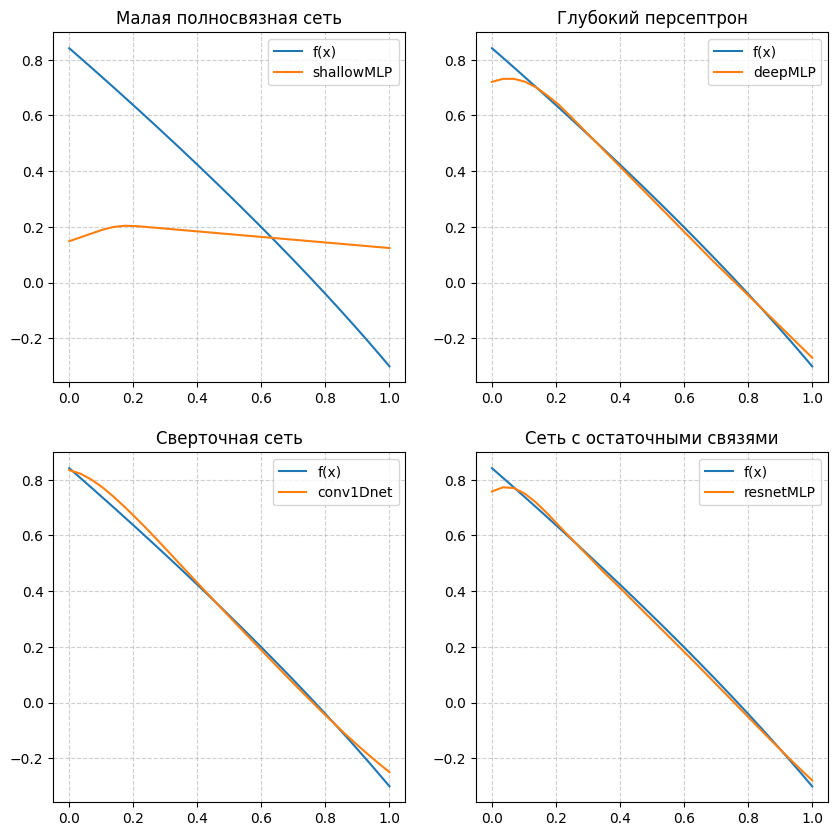

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

axes[0].plot(x, func(x), label='f(x)')
axes[0].plot(x_test, y_pred_shallow, label='shallowMLP')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_title('Малая полносвязная сеть')
axes[0].legend()

axes[1].plot(x, func(x), label='f(x)')
axes[1].plot(x_test, y_pred_deep, label='deepMLP')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].set_title('Глубокий персептрон')
axes[1].legend()

axes[2].plot(x, func(x), label='f(x)')
axes[2].plot(x_test, y_pred_conv, label='conv1Dnet')
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].set_title('Сверточная сеть')
axes[2].legend()

axes[3].plot(x, func(x), label='f(x)')
axes[3].plot(x_test, y_pred_resnet, label='resnetMLP')
axes[3].grid(True, linestyle='--', alpha=0.6)
axes[3].set_title('Сеть с остаточными связями')
axes[3].legend()

plt.savefig('graf.png', dpi = 300)
plt.show()

### Экстраполяция сверточной нейронной сети:

In [63]:
x_left = np.linspace(a-1.5, a, 50).reshape(-1, 1)
y_left = func(x_left).reshape(-1, 1)
x_right = np.linspace(b, b+0.5, 50).reshape(-1, 1)
y_right = func(x_right).reshape(-1, 1)

y_conv_left = model_conv.predict(x_left)
y_conv_right = model_conv.predict(x_right)

mse_conv_left = mean_squared_error(y_left, y_conv_left)
mae_conv_left = mean_absolute_error(y_left, y_conv_left)
r2_conv_left = r2_score(y_left, y_conv_left)

mse_conv_right = mean_squared_error(y_right, y_conv_right)
mae_conv_right = mean_absolute_error(y_right, y_conv_right)
r2_conv_right = r2_score(y_right, y_conv_right)

print("convMLP left:")
print("mse: ", mse_conv_left)
print("mae: ", mae_conv_left)
print("r2: ", r2_conv_left)

print("convMLP right:")
print("mse: ", mse_conv_right)
print("mae: ", mae_conv_right)
print("r2: ", r2_conv_right)



2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
convMLP left:
mse:  0.9676233061586055
mae:  0.8571043474190628
r2:  -8.473084997384843
convMLP right:
mse:  0.08831363505415013
mae:  0.25566467162683376
r2:  -0.35092555901768363


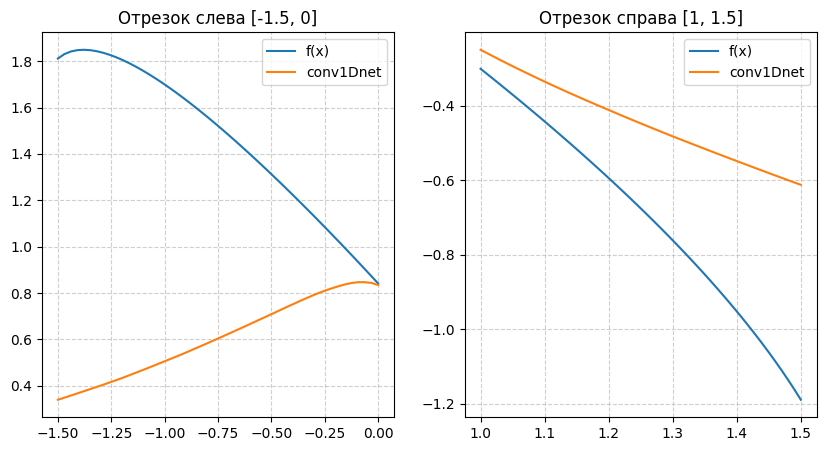

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = axes.flatten()

axes[0].plot(x_left, y_left, label='f(x)')
axes[0].plot(x_left, y_conv_left, label='conv1Dnet')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_title('Отрезок слева [-1.5, 0]')
axes[0].legend()

axes[1].plot(x_right, y_right, label='f(x)')
axes[1].plot(x_right, y_conv_right, label='conv1Dnet')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].set_title('Отрезок справа [1, 1.5]')
axes[1].legend()

plt.savefig('left_right.png', dpi = 300)
plt.show()